# 08 · Executive Report & Recommendations
*EV capacity planning for PowerCharge Utilities · notebook 8 of 8 · Anna Tafri*

Reads: Outputs of Notebooks 01–07 (`reports/*.csv`, `data/processed/*.csv`)  
Writes: `reports/executive_summary.png`, `reports/recommendations.csv`

> Every number in this report is computed from the saved outputs of earlier notebooks, never typed in by hand. If the data or an assumption changes, re-running notebooks 01–08 refreshes the whole report.


## Executive summary

**Bottom line:** PowerCharge's network is not at risk from EV charging today. However, 9 substations will breach their planning limit if EV load grows 20×, a realistic medium-term horizon. An optimised mix of transformer uprates and non-wire alternatives (smart charging, time-of-use tariffs, batteries) keeps the network compliant for about 40% less than reinforcing alone.

**Three decisions for the executive team:**
1. Fund a 3-month data-validation sprint now. The station-to-substation connectivity in the data cannot be physically correct, and existing base load is the single biggest unknown. Both decide *which* substations need money.
2. Approve the no-regret package in principle, with release conditional on the sprint confirming connectivity at those sites. These actions are needed under every base-load assumption we tested.
3. Adopt trigger-based investment. Release each upgrade when measured EV peak at a substation reaches its trigger, instead of building on forecasts.

The cells below compute the supporting figures.

## 0. Setup: load every upstream output

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED = PROJECT_ROOT / "data" / "processed"
RAW = PROJECT_ROOT / "data" / "raw"
REPORTS = PROJECT_ROOT / "reports"
FIGURES = REPORTS / "figures"
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from ev_utils import capacity_model

pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_colwidth", 120)

INK, INK_2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#8a8984", "#e4e3df", "#fcfcfb"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
CRITICAL, WARNING = "#d03b3b", "#fab219"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK_2, "axes.edgecolor": GRID, "text.color": INK,
    "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False,
})

raw_ev = pd.read_csv(RAW / "ev_distribution_dataset.csv")
events = pd.read_csv(PROCESSED / "ev_events_clean.csv", parse_dates=["timestamp"])
subs = pd.read_csv(PROCESSED / "substations_clean.csv")
capacity = pd.read_csv(PROCESSED / "substation_capacity.csv", index_col="substation_id")
scores = pd.read_csv(PROCESSED / "bottleneck_scores.csv", index_col="substation_id")
scenarios = pd.read_csv(REPORTS / "capacity_scenarios.csv")
dq_log = pd.read_csv(REPORTS / "data_quality_log.csv")
plan = pd.read_csv(REPORTS / "upgrade_plan.csv", index_col="substation_id")
no_regret = pd.read_csv(REPORTS / "no_regret_actions.csv", index_col="substation_id")
frontier = pd.read_csv(REPORTS / "budget_frontier.csv")
cost_cmp = pd.read_csv(REPORTS / "plan_cost_comparison.csv", index_col=0)
print("All upstream outputs loaded.")

All upstream outputs loaded.


## 1. Key metrics

In [2]:
KWH = "electricity_consumption_kwh"
CHARGER_KW = {"Type 1": 7.4, "Type 2": 22.0, "DC Fast": 50.0}

base_breach = capacity.index[capacity["util_20x"] >= 0.80]
tier1 = scores.index[scores["tier"] == "Tier 1 - Act"]
tier2 = scores.index[scores["tier"] == "Tier 2 - Plan"]
peak_share = events.loc[events["is_peak_hour"], KWH].sum() / events[KWH].sum()
half_risk_budget = frontier.loc[frontier["risk_covered_pct"] >= 0.5, "budget_musd"].min()

kpi = {
    "Raw EV records -> unique events": f"{len(raw_ev)} -> {len(events)}",
    "Share of energy in 17:00-21:00 peak": f"{peak_share:.0%}",
    "Substations above planning limit today": int((capacity["utilisation"] >= 0.80).sum()),
    "Highest peak utilisation today": f"{capacity['utilisation'].max():.0%}",
    "First substation to breach": f"{capacity['breaking_multiple'].idxmin()} at {capacity['breaking_multiple'].min():.1f}x today's EV load",
    "Substations breaching at 20x growth (base case)": len(base_breach),
    "Tier 1 (act) / Tier 2 (plan) bottlenecks": f"{len(tier1)} / {len(tier2)}",
    "Optimised plan vs reinforce-only (base case)": f"${cost_cmp.iloc[0]['optimised cost ($M)']:.1f}M vs ${cost_cmp.iloc[0]['reinforce-only cost ($M)']:.1f}M ({cost_cmp.iloc[0]['saving (%)']:.0%} saving)",
    "Robust upgrade plan (70% base load)": f"${plan['cost ($M)'].sum():.1f}M across {len(plan)} substations",
    "No-regret package": f"${no_regret['cost_musd'].sum():.1f}M across {len(no_regret)} substations",
    "Budget to resolve 50% of network risk": f"${half_risk_budget:.1f}M",
}
pd.Series(kpi, name="value").to_frame()

,value
Raw EV records -> unique events,500 -> 97
Share of energy in 17:00-21:00 peak,25%
Substations above planning limit today,0
Highest peak utilisation today,67%
First substation to breach,Substation_258 at 9.4x today's EV load
Substations breaching at 20x growth (base case),9
Tier 1 (act) / Tier 2 (plan) bottlenecks,9 / 10
Optimised plan vs reinforce-only (base case),$5.4M vs $9.0M (40% saving)
Robust upgrade plan (70% base load),$12.4M across 17 substations
No-regret package,$4.4M across 6 substations


## 2. Findings

### Finding 1: the data needed serious repair before it could be trusted
81% of EV records were exact duplicates, one substation ID was duplicated, weather labels contradicted temperatures, and energy (kWh) had to be converted into power (MW). Seven issues were logged and resolved with documented decisions.

In [3]:
dq_log[['id', 'issue', 'impact', 'decision']]

,id,issue,impact,decision
0,DQ-01,Exact duplicate rows,High,Drop exact duplicates before any aggregation
1,DQ-02,Substation_ID not unique,High,Split into _A/_B and allocate EV records by nearest location
2,DQ-03,Weather label contradicts temperature,Medium,Use temperature/precipitation; flag label as low-confidence
3,DQ-04,Coordinates stored as text tuples,Low,Parse into numeric lat/lon columns
4,DQ-05,Geographic footprint is unrealistic,Low,Use maps for relative patterns only; note in report
5,DQ-06,Unit mismatch: kWh vs MW,High,Convert with an explicit charging-window assumption plus sensitivity test
6,DQ-07,"Short history, small sample",Medium,Scenario-based growth instead of time-series forecasting


### Finding 2: load is driven by *volume and charger speed*, not by customer type
- The evening window (17:00–21:00) carries ~25% of the energy in 17% of the hours. 19:00 is the busiest hour.
- Energy per charging event is statistically the same across every segment: area, customer type, EV type, charger type, and habit.
- DC fast chargers deliver the same energy in less time, so they raise peak power. They account for 81–93% of connected EV power at bottleneck substations, compared with 17% elsewhere.

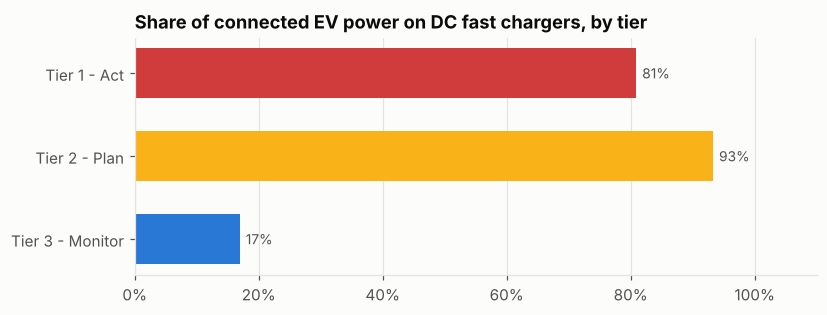

In [4]:
fs = scores.groupby("tier")["fast_charger_share"].mean()
fig, ax = plt.subplots(figsize=(8, 2.8))
colors = {"Tier 1 - Act": CRITICAL, "Tier 2 - Plan": WARNING, "Tier 3 - Monitor": SERIES[0]}
ax.barh(fs.index[::-1], fs.values[::-1], color=[colors[t] for t in fs.index[::-1]], height=0.6)
for yi, v in enumerate(fs.values[::-1]):
    ax.text(v + 0.01, yi, f"{v:.0%}", va="center", fontsize=9, color=INK_2)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set(title="Share of connected EV power on DC fast chargers, by tier", xlim=(0, 1.1))
ax.grid(axis="y", visible=False)
fig.savefig(FIGURES / "08_01_fast_charger_by_tier.png"); plt.show()

### Finding 3: there is headroom today, but it runs out unevenly
No substation is at risk now; the highest peak utilisation is 67%. As EV load grows, small substations with several fast-charging sites run out first.

In [5]:
scenarios[['scenario', 'max_utilisation', 'within_limit', 'above_limit', 'overloaded']]

,scenario,max_utilisation,within_limit,above_limit,overloaded
0,Today,0.67,50,0,0
1,Low (5x),0.73,50,0,0
2,Medium (10x),0.81,49,1,0
3,High (20x),0.97,41,9,0
4,Stress (40x),1.29,24,21,5


### Finding 4: an optimised mix beats reinforcement, even under pessimistic assumptions
Non-wire alternatives handle most at-risk substations. Only the largest deficits need new transformer capacity. The optimised plan stays cheaper than reinforce-only even if non-wire options deliver just 50% of their planned relief (Notebook 06, section 6).

In [6]:
action = plan.apply(lambda r: "Wire (uprate)" if r["uprates"] > 0 or r["new bay"] > 0 else "Non-wire only", axis=1)
plan.assign(action=action).groupby("action").agg(substations=("cost ($M)", "size"), cost_musd=("cost ($M)", "sum"))

,substations,cost_musd
action,,
Non-wire only,10,3.56
Wire (uprate),7,8.79


### Finding 5: two data gaps decide *where* the money goes
- **Base load:** moving the assumed existing base load from 55% to 75% changes the number of at-risk substations at 10× growth from 0 to 18 (Notebook 04).
- **Connectivity:** none of the 97 charging stations is linked to its nearest substation. A geographic re-allocation keeps the *number* of bottlenecks similar, but only 3 substations appear on both lists (Notebook 07).

The method is robust, but the list of substations to fund is only as good as these two inputs. That is why data validation is recommendation #1, ahead of any capex release.

## 3. Recommendations

In [7]:
nr_cost = no_regret["cost_musd"].sum()
phase1 = plan[plan["phase"].str.startswith("Phase 1")]
nonwire_subs = plan.index[(plan["uprates"] == 0) & (plan["new bay"] == 0)]

recs = pd.DataFrame([
    {"#": 1, "recommendation": "Run a data-validation sprint before releasing capex",
     "detail": "Reconcile station-to-substation connectivity with the GIS / asset register and pull 12 months of SCADA peak load for Tier 1-2 substations, then re-run notebooks 04-07",
     "cost": "Low (internal data and GIS team)", "owner": "Data & GIS", "timing": "0-3 months"},
    {"#": 2, "recommendation": "Approve the no-regret package in principle",
     "detail": f"Uprates and targeted non-wire measures at {len(no_regret)} substations ({', '.join(s.replace('Substation_', 'S') for s in no_regret.index)}), required under every base-load assumption. Release once rec. #1 confirms connectivity at these sites",
     "cost": f"${nr_cost:.1f}M", "owner": "Network Planning", "timing": "Approve now, release after rec. #1"},
    {"#": 3, "recommendation": "Pilot time-of-use tariffs and smart charging",
     "detail": f"Start where non-wire options are the planned fix ({len(nonwire_subs)} substations) and measure real peak reduction against the 10% / 25% planning assumptions",
     "cost": "Included in plan", "owner": "Customer & Pricing", "timing": "3-9 months"},
    {"#": 4, "recommendation": "Introduce a DC fast-charger connection review",
     "detail": "Any new DC fast-charger connection at a Tier 1-2 substation triggers a capacity check, with managed charging or a battery buffer as a connection condition where headroom is thin",
     "cost": "Policy (no capex)", "owner": "Connections", "timing": "0-6 months"},
    {"#": 5, "recommendation": "Fund the remaining plan on triggers, not dates",
     "detail": f"Release each upgrade when measured EV peak reaches its trigger multiple. Phase 1 covers {len(phase1)} substations (${phase1['cost ($M)'].sum():.1f}M); full robust plan ${plan['cost ($M)'].sum():.1f}M",
     "cost": f"Up to ${plan['cost ($M)'].sum() - nr_cost:.1f}M beyond no-regret", "owner": "Finance & Planning", "timing": "Ongoing"},
    {"#": 6, "recommendation": "Build an EV capacity monitoring dashboard",
     "detail": "Track EV peak per substation against its breaking multiple and trigger, refreshed monthly from metering data",
     "cost": "Low", "owner": "Analytics", "timing": "3-6 months"},
])
recs.to_csv(REPORTS / "recommendations.csv", index=False)
recs

,#,recommendation,detail,cost,owner,timing
0,1,Run a data-validation sprint before releasing capex,Reconcile station-to-substation connectivity with the GIS / asset register and pull 12 months of SCADA peak load for...,Low (internal data and GIS team),Data & GIS,0-3 months
1,2,Approve the no-regret package in principle,"Uprates and targeted non-wire measures at 6 substations (S560, S258, S301, S516, S470, S11_B), required under every ...",$4.4M,Network Planning,"Approve now, release after rec. #1"
2,3,Pilot time-of-use tariffs and smart charging,Start where non-wire options are the planned fix (10 substations) and measure real peak reduction against the 10% / ...,Included in plan,Customer & Pricing,3-9 months
3,4,Introduce a DC fast-charger connection review,"Any new DC fast-charger connection at a Tier 1-2 substation triggers a capacity check, with managed charging or a ba...",Policy (no capex),Connections,0-6 months
4,5,"Fund the remaining plan on triggers, not dates",Release each upgrade when measured EV peak reaches its trigger multiple. Phase 1 covers 3 substations ($4.8M); full ...,Up to $8.0M beyond no-regret,Finance & Planning,Ongoing
5,6,Build an EV capacity monitoring dashboard,"Track EV peak per substation against its breaking multiple and trigger, refreshed monthly from metering data",Low,Analytics,3-6 months


## 4. Expected benefits
| Business goal (from the brief) | How this plan delivers it |
|---|---|
| Customer retention and satisfaction | Every substation stays within its planning limit at 20× EV growth, so overloads and outages are avoided at the sites EV owners rely on |
| Revenue growth | Headroom is created where charging demand is growing, so new charging connections can be accepted instead of refused |
| Cost management | About 40% cheaper than reinforce-only, and spending is released only when growth actually arrives |
| Sustainability | Smart charging and tariffs make better use of existing assets and shift load to off-peak hours |
| Regulatory compliance | A documented, assumption-tested, data-quality-logged method supports regulatory capacity-planning submissions |

## 5. Risks and limitations
| Limitation | Impact | Mitigation |
|---|---|---|
| Small sample: 97 events over 38 days | No growth forecast possible; seasonal effects untested | Scenario-based planning and trigger-based investment; collect 12+ months of data |
| No base-load data | Largest single uncertainty in the at-risk list | Robust (70%) plan plus SCADA data pull (rec. #1) |
| Connectivity cannot be physically right | The *which* substations answer could change | Validation sprint before any capex is released (rec. #1) |
| Indicative unit costs | Absolute $ figures are approximate | Costs sit in one table; replace with PowerCharge's own rates and re-run |
| Synthetic coordinates span a continent | Maps show relative patterns, not a real territory | Re-run Notebook 07 on real GIS data |
| Non-wire delivery uncertainty | Smart charging and tariffs may under-deliver | Plan stays cheaper at 50% delivery; pilot first (rec. #3) |

## 6. One-page executive summary
A single shareable page for the executive pack.

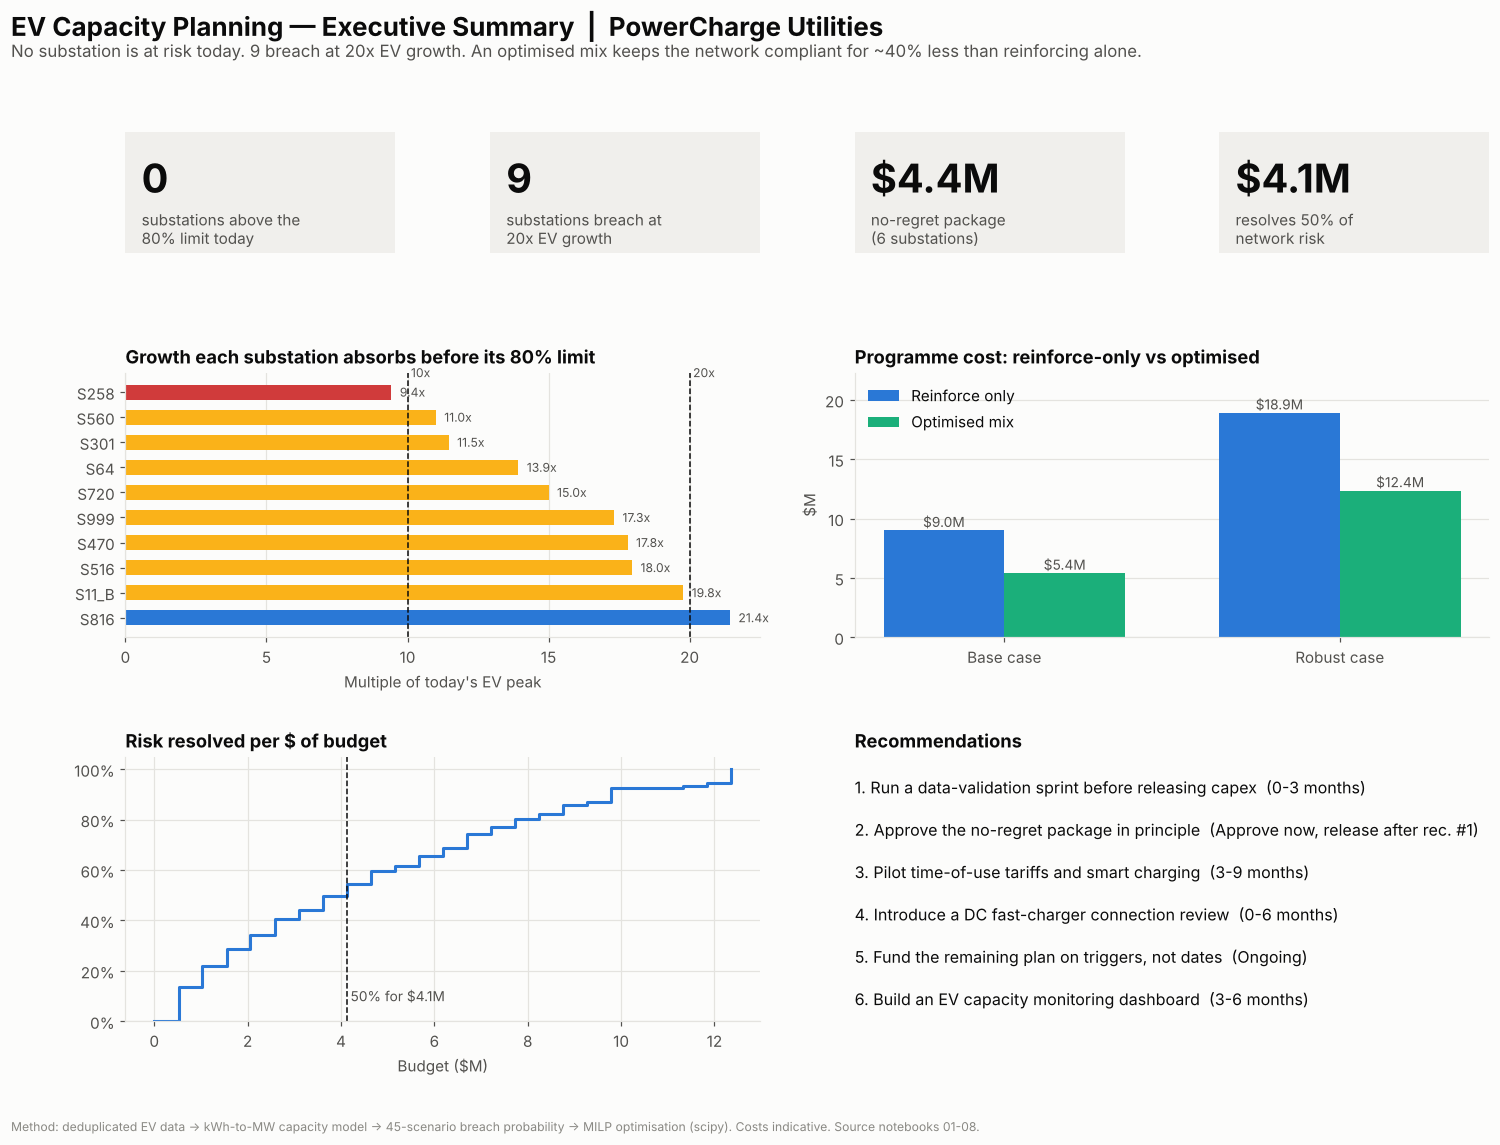

In [8]:
fig = plt.figure(figsize=(16, 10.5))
gs = fig.add_gridspec(3, 4, height_ratios=[0.55, 1.2, 1.2], hspace=0.55, wspace=0.35)
fig.suptitle("EV Capacity Planning — Executive Summary  |  PowerCharge Utilities", x=0.06, y=0.985, ha="left",
             fontsize=17, fontweight="bold")
fig.text(0.06, 0.945, "No substation is at risk today. 9 breach at 20x EV growth. An optimised mix keeps the network compliant "
         "for ~40% less than reinforcing alone.", fontsize=11, color=INK_2)

tiles = [
    (f"{int((capacity['utilisation'] >= 0.8).sum())}", "substations above the\n80% limit today"),
    (f"{len(base_breach)}", "substations breach at\n20x EV growth"),
    (f"${no_regret['cost_musd'].sum():.1f}M", f"no-regret package\n({len(no_regret)} substations)"),
    (f"${half_risk_budget:.1f}M", "resolves 50% of\nnetwork risk"),
]
for i, (big, small) in enumerate(tiles):
    ax = fig.add_subplot(gs[0, i]); ax.set_axis_off()
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, transform=ax.transAxes, color="#f0efec", zorder=0))
    ax.text(0.06, 0.62, big, fontsize=26, fontweight="bold", color=INK, transform=ax.transAxes, va="center")
    ax.text(0.06, 0.2, small, fontsize=10, color=INK_2, transform=ax.transAxes, va="center")

# Breaking multiple
ax = fig.add_subplot(gs[1, :2])
brk = capacity["breaking_multiple"].dropna().sort_values().head(10).iloc[::-1]
ax.barh([s.replace("Substation_", "S") for s in brk.index], brk.values,
        color=[CRITICAL if v <= 10 else WARNING if v <= 20 else SERIES[0] for v in brk.values], height=0.6)
for x in (10, 20):
    ax.axvline(x, color=INK, linestyle="--", linewidth=1)
    ax.text(x, 9.6, f" {x}x", fontsize=8, color=INK_2)
for yi, v in enumerate(brk.values):
    ax.text(v + 0.3, yi, f"{v:.1f}x", va="center", fontsize=8, color=INK_2)
ax.set(title="Growth each substation absorbs before its 80% limit", xlabel="Multiple of today's EV peak")
ax.grid(axis="y", visible=False)

# Cost comparison
ax = fig.add_subplot(gs[1, 2:])
cost_tbl = pd.DataFrame({"Reinforce only": cost_cmp["reinforce-only cost ($M)"].values,
                         "Optimised mix": cost_cmp["optimised cost ($M)"].values}, index=["Base case", "Robust case"])
x = np.arange(2); w = 0.36
for j, (col, color) in enumerate(zip(cost_tbl.columns, [SERIES[0], SERIES[2]])):
    ax.bar(x + (j - 0.5) * w, cost_tbl[col], width=w, color=color, label=col)
    for xi, v in zip(x, cost_tbl[col]):
        ax.text(xi + (j - 0.5) * w, v + 0.3, f"${v:.1f}M", ha="center", fontsize=9, color=INK_2)
ax.set_xticks(x, cost_tbl.index)
ax.set(title="Programme cost: reinforce-only vs optimised", ylabel="$M", ylim=(0, cost_tbl.values.max() * 1.18))
ax.legend(loc="upper left"); ax.grid(axis="x", visible=False)

# Frontier
ax = fig.add_subplot(gs[2, :2])
ax.step(frontier["budget_musd"], frontier["risk_covered_pct"], where="post", color=SERIES[0], linewidth=2)
ax.axvline(half_risk_budget, color=INK, linestyle="--", linewidth=1)
ax.text(half_risk_budget, 0.08, f" 50% for ${half_risk_budget:.1f}M", fontsize=9, color=INK_2)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set(title="Risk resolved per $ of budget", xlabel="Budget ($M)", ylim=(0, 1.05))

# Recommendations
ax = fig.add_subplot(gs[2, 2:]); ax.set_axis_off()
ax.set_title("Recommendations", loc="left")
lines = [f"{r['#']}. {r['recommendation']}  ({r['timing']})" for _, r in recs.iterrows()]
for i, line in enumerate(lines):
    ax.text(0.0, 0.92 - i * 0.16, line, fontsize=10.5, color=INK, transform=ax.transAxes, va="top")

fig.text(0.06, 0.015, "Method: deduplicated EV data -> kWh-to-MW capacity model -> 45-scenario breach probability -> MILP optimisation "
         "(scipy). Costs indicative. Source notebooks 01-08.", fontsize=8, color=MUTED)
fig.savefig(REPORTS / "executive_summary.png")
plt.show()

## 7. What I'd do next
With more time or better data, I would:
- Use 12+ months of interval metering and SCADA data, so EV peak can be modelled from real coincident load instead of nameplate ratings.
- Run a full Monte Carlo simulation with distributions on each assumption, replacing the 45-scenario grid.
- Add a time dimension to the optimisation: multi-year staging with discounting and lead times.
- Add power-flow modelling (for example `pandapower`) to check voltage limits on long feeders as well as thermal capacity.

